In [20]:
from cmath import sqrt
from pathlib import Path
import diffusers.optimization
import pandas as pd
import numpy as np
from pathlib import Path
import torch
from torch.utils.data import TensorDataset
import matplotlib.pyplot as plt

In [76]:
ts = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\Generation\results\run_000005.h5", key="timeseries")

In [77]:
params = pd.read_hdf(r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\Generation\results\run_000005.h5", key="params")
params

,country,buildingType,surrounding,buildingAgeBin,a_ref,n_apartments,year_type,future,climateRegion,n_persons,...,weatherID,resolved_climateRegion,resolved_latitude,resolved_longitude,state_seed,apartment_seeds,appliances,maxLoadViolation_kW,runtime_seconds,resolved_year
0,DE,SFH,Detached,DE.06,193.6,1,average,False,12,[2],...,TRY2015_12_average_TRY2015_501182088054_Jahr,12,50.1182,8.8054,1000005,[8170882],"[[""FRIDGE_FREEZER"", ""FRIDGE"", ""ANSWER_MACHINE""...",2.898075e-14,80.580153,2025


In [70]:
resultsdir = Path(r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\Generation")
completed_runs = sorted(resultsdir.glob("run_*.h5"))

In [78]:
ts

,T,Occupancy Home Active,Occupancy Home Not Active,Electricity Load,Hot Water Load,Heating Load,Off Day
2025-01-01 00:00:00+01:00,-0.9,0.0,1.0,0.058234,0.0,5.385796,1
2025-01-01 00:01:00+01:00,-0.9,0.0,1.0,0.058234,0.0,5.385796,1
2025-01-01 00:02:00+01:00,-0.9,0.0,1.0,0.058234,0.0,5.385796,1
2025-01-01 00:03:00+01:00,-0.9,0.0,1.0,0.058234,0.0,5.385796,1
2025-01-01 00:04:00+01:00,-0.9,0.0,1.0,0.058234,0.0,5.385796,1
...,...,...,...,...,...,...,...
2025-12-31 23:55:00+01:00,0.5,0.0,2.0,0.057999,0.0,3.582321,0
2025-12-31 23:56:00+01:00,0.5,0.0,2.0,0.057999,0.0,3.582321,0
2025-12-31 23:57:00+01:00,0.5,0.0,2.0,0.057999,0.0,3.582321,0
2025-12-31 23:58:00+01:00,0.5,0.0,2.0,0.057999,0.0,3.582321,0


<Axes: >

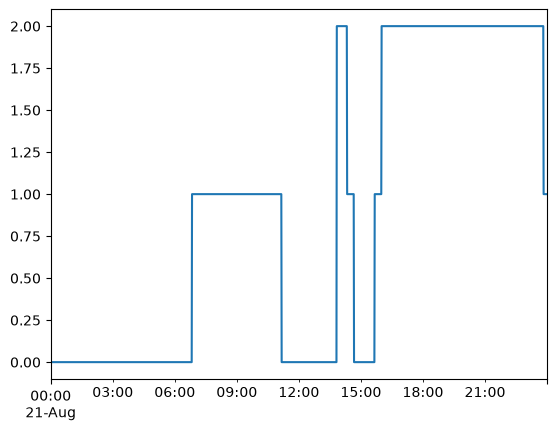

In [72]:
ts["Occupancy Home Active"].loc["2010-08-21"].plot()

In [27]:
for run in completed_runs:
    ts = pd.read_hdf(run,key="timeseries" )
    ts = ts["Occupancy Home Active"]
    res = (ts.to_numpy().reshape(-1, 1440).min(1) >0).sum()
    print(res)

122
98
114
120
113
122
75
78
84
104
110
105
129
111
127
144
144
136
121
114
100
27
25
28
125
141
126
94
101
90
87
99
85
44
48
38
91
103
103
94
97
94
39
34
40
53
64
68
111
91
108
115
101
107
95
77
73
89
79
101
66
61
71
126
106
105
114
119
102
50
58
43
126
106
99
122
120
125
134
122
130
52
42
49
100
116
109
99
93
89
121
119
131
83
89
86
66
76
85
117
113
99
35
45
54
186
169
160
69
84
79
101
97
115
67
60
69
137
130
144
123
109
111
94
98
103
62
52
41
107
78
74
115
116
102
53
69
46
82
101
85
139
150
137
38
43
48
95
100
113
135
108
136
50
49
60
129
114
123
29
34
29
17
14
15
49
50
66
77
69
82
97
114
104
67
60
55
72
66
75
110
101
102
53
53
54
102
98
95
78
56
59
93
101
99
129
116
131
107
116
120
119
95
111
111
102
119
123
137
119
32
34
36
166
180
173
92
105
102
99
98
90
50
58
58
100
102
86
103
117
106
96
99
113
67
66
58
120
123
134
163
148
147
73
48
46
121
130
130
160
161
150
70
69
83
74
79
81
74
81
74
86
67
61
125
117
124
36
37
34
73
88
83
124
134
102
81
98
80
68
78
73
62
62
57
83
94
100
105
98

In [36]:
series_t = ts["Occupancy Home Active"]
#(single.occ_active.reshape(-1, 144).min(1) > 0).sum()

In [39]:
sum(series_t.to_numpy().reshape(-1, 1440).min(1) >0)

np.int64(5)

In [5]:
from pathlib import Path
import pandas as pd

RESULTS_DIR = Path(r"C:\Users\Samuel\FH_Aachen\tsib_simuflex_fork\tsib_simuflex\Generation")
completed_runs = RESULTS_DIR.glob("run_*.h5")

series = []

for run in completed_runs:
    ts = pd.read_hdf(run, key="timeseries")

    load = ts["Occupancy Home Active"].rename(run.stem)
    series.append(load)

combined = pd.concat(series, axis=1)

In [6]:
combined_15min = combined.resample("15min").mean()

In [7]:
train = combined.iloc[:, :1]
val = combined.iloc[:, :1]

In [8]:
def window_data(df, window_length):
    windows = []
    for column in df.columns:
        series = df[column].to_numpy(dtype=np.float32)
        for step in range(0, len(series) - window_length+1,window_length):
            window = series[step:step+window_length]
            windows.append(window)
    windows = np.stack(windows)
    windows = torch.from_numpy(windows).unsqueeze(1)
    return windows

In [9]:
train_tensor = window_data(train, 1440)
val_tensor = window_data(val,1440)

In [10]:
train_log = torch.log1p(train_tensor)

log_mean = train_log.mean(dim=(0, 2), keepdim=True)
log_std = train_log.std(dim=(0, 2), keepdim=True)

train_tensor_norm = (train_log - log_mean) / log_std

val_log = torch.log1p(val_tensor)
val_tensor_norm = (val_log - log_mean) / log_std

In [11]:
print(train_tensor_norm.min())
print(train_tensor_norm.max())
print(train_tensor_norm.mean())
print(train_tensor_norm.std())

tensor(-2.2585)
tensor(1.4138)
tensor(-1.5828e-07)
tensor(1.0000)


In [12]:
train_tensor_norm_set = TensorDataset(train_tensor_norm)
val_tensor_norm_set = TensorDataset(val_tensor_norm)

In [13]:
train_tensor.shape

torch.Size([365, 1, 1440])

In [17]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)